In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)
    
    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt
    
    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


# Support Vector Regression
## Temperature

In [ ]:
import numpy as np
import pandas as pd
import src.utils.metrics as metrics
import matplotlib.pyplot as plt

from joblib import Parallel, delayed
from sklearn.svm import SVR, LinearSVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.data.preprocessing import get_split

def make_svr(kernel, params):
    if kernel == "linear":
        svr = LinearSVR(max_iter=20000, random_state=0, **params)
    else:
        svr = SVR(kernel=kernel, **params)
    return make_pipeline(StandardScaler(), svr)  # SVR needs scaled features

# SVR predicts a single value, so each lead time h gets its own fit
def svr_val_mae(kernel, params, h):
    svr = make_svr(kernel, params).fit(X_train, y_train[h])
    return metrics.get_mean_absolute_error(y_val[h], svr.predict(X_val))


split = get_split()
features = split.get_features()
split.define_target("t2m_mean")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = split.get(features)

# Candidate kernels with a small hyperparameter grid each
candidates = (
    [("linear", {"C": C}) for C in (0.1, 1, 10)]
    + [("poly", {"degree": d, "C": C, "coef0": 1}) for d in (2, 3) for C in (0.1, 1, 10)]
    + [("rbf", {"C": C, "gamma": gamma}) for C in (1, 10, 100) for gamma in (0.003, 0.01, 0.03)]
)

# One job per (candidate, lead time): 18 x 30 = 540 fits over all CPU cores
maes = Parallel(n_jobs=-1)(
    delayed(svr_val_mae)(kernel, params, h) for kernel, params in candidates for h in y_train.columns
)
mae_by_h = np.array(maes).reshape(len(candidates), len(y_train.columns))  # rows: candidates, cols: lead times
scores = mae_by_h.mean(axis=1)  # validation MAE averaged over the 30 lead times

kernel_scores = pd.DataFrame(
    [(kernel, str(params), score) for (kernel, params), score in zip(candidates, scores)],
    columns=["Kernel", "Best params", "Val MAE"],
)

# Best configuration of each kernel
kernel_table = kernel_scores.loc[kernel_scores.groupby("Kernel")["Val MAE"].idxmin()].set_index("Kernel")

display(kernel_table.sort_values("Val MAE").round(4))

,Best params,Val MAE
Kernel,,
(Linear Regression),-,2.0515
linear,{'C': 10},2.0523
rbf,"{'C': 10, 'gamma': 0.003}",2.0618
poly,"{'degree': 2, 'C': 1, 'coef0': 1}",2.0781


Best: linear {'C': 10}


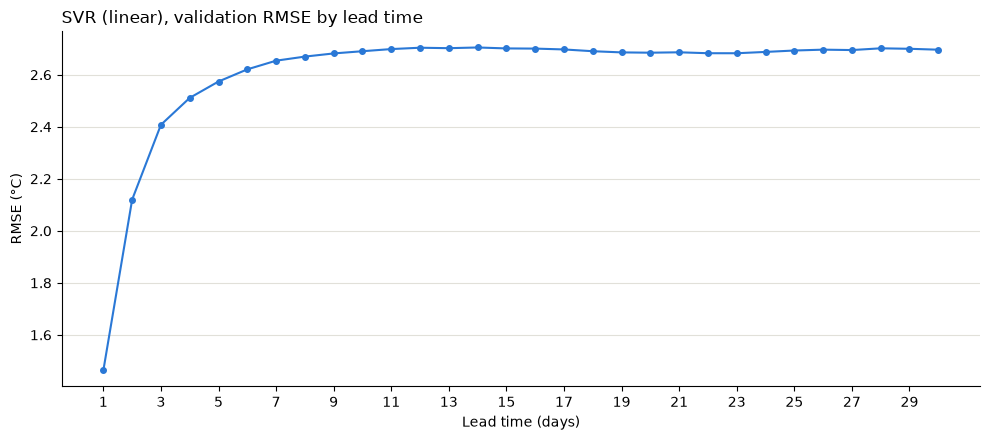

In [3]:
from sklearn.multioutput import MultiOutputRegressor

best_kernel, best_params = candidates[int(np.argmin(scores))]
print("Best:", best_kernel, best_params)

svr = MultiOutputRegressor(make_svr(best_kernel, best_params), n_jobs=-1).fit(X_train, y_train)

y_train_pred = svr.predict(X_train)
y_val_pred = svr.predict(X_val)
y_test_pred = svr.predict(X_test)

metrics.plot_rmse(y_val, y_val_pred, f"SVR ({best_kernel}), validation RMSE by lead time", "°C")

table = metrics.metrics_table(
    {"Train": (y_train, y_train_pred), "Val": (y_val, y_val_pred), "Test": (y_test, y_test_pred)},
    tolerance=2,
)
display(table.style.format("{:.3f}"))

## Precipitations

In [ ]:
split_p = get_split()
features = split_p.get_features()
split_p.define_target("tp_mm")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = split_p.get(features)

# Candidate kernels with a small hyperparameter grid each
candidates = (
    [("linear", {"C": C}) for C in (0.1, 1, 10)]
    + [("poly", {"degree": d, "C": C, "coef0": 1}) for d in (2, 3) for C in (0.1, 1, 10)]
    + [("rbf", {"C": C, "gamma": gamma}) for C in (1, 10, 100) for gamma in (0.003, 0.01, 0.03)]
)

# One job per (candidate, lead time): 18 x 30 = 540 fits over all CPU cores
maes = Parallel(n_jobs=-1)(
    delayed(svr_val_mae)(kernel, params, h) for kernel, params in candidates for h in y_train.columns
)
mae_by_h = np.array(maes).reshape(len(candidates), len(y_train.columns))  # rows: candidates, cols: lead times
scores = mae_by_h.mean(axis=1)  # validation MAE averaged over the 30 lead times

kernel_scores = pd.DataFrame(
    [(kernel, str(params), score) for (kernel, params), score in zip(candidates, scores)],
    columns=["Kernel", "Best params", "Val MAE"],
)

# Best configuration of each kernel
kernel_table = kernel_scores.loc[kernel_scores.groupby("Kernel")["Val MAE"].idxmin()].set_index("Kernel")

display(kernel_table.sort_values("Val MAE").round(4))

In [ ]:
best_kernel, best_params = candidates[int(np.argmin(scores))]
print("Best:", best_kernel, best_params)

svr = MultiOutputRegressor(make_svr(best_kernel, best_params), n_jobs=-1).fit(X_train, y_train)

y_train_pred = svr.predict(X_train)
y_val_pred = svr.predict(X_val)
y_test_pred = svr.predict(X_test)

metrics.plot_rmse(y_val, y_val_pred, f"SVR ({best_kernel}), validation RMSE by lead time", "mm")

table = metrics.metrics_table(
    {"Train": (y_train, y_train_pred), "Val": (y_val, y_val_pred), "Test": (y_test, y_test_pred)},
    tolerance=2,
)
display(table.style.format("{:.3f}"))

## "Joint"

In [5]:
split_j = get_split()
features = split_j.get_features()

# Temperature targets
split_j.define_target("t2m_mean")
(X_train, yt_train), (X_val, yt_val), (X_test, yt_test) = split_j.get(features)

# Precipitation targets
split_j.define_target("tp_mm")
(_, yp_train), (_, yp_val), (_, yp_test) = split_j.get(features)

y_train = pd.concat({"t2m_mean": yt_train, "tp_mm": yp_train}, axis=1)
y_val   = pd.concat({"t2m_mean": yt_val,   "tp_mm": yp_val},   axis=1)
y_test  = pd.concat({"t2m_mean": yt_test,  "tp_mm": yp_test},  axis=1)

In [6]:
joint = make_pipeline(
    StandardScaler(),
    MultiOutputRegressor(SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"), n_jobs=-1),
)
joint.fit(X_train, y_train)

# Predictions with the same (target, lead time) columns as y
def predict_df(X, y):
    pred = pd.DataFrame(joint.predict(X), index=y.index, columns=y.columns)
    pred["tp_mm"] = pred["tp_mm"].clip(lower=0)  # rain >= 0
    return pred

y_train_pred = predict_df(X_train, y_train)
y_val_pred   = predict_df(X_val, y_val)
y_test_pred  = predict_df(X_test, y_test)

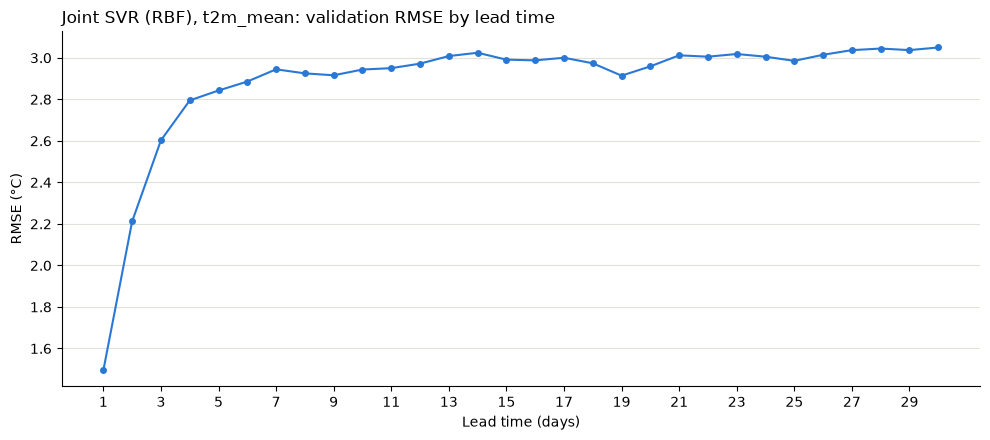

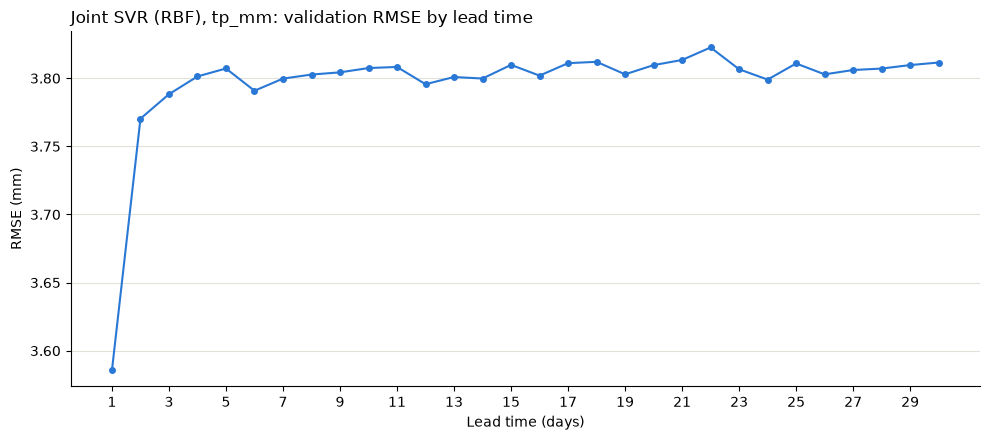

In [7]:
for target, unit, tol in [("t2m_mean", "°C", 2), ("tp_mm", "mm", None)]:
    metrics.plot_rmse(y_val[target], y_val_pred[target],
                      f"Joint SVR (RBF), {target}: validation RMSE by lead time", unit)

    table = metrics.metrics_table(
        {"Train": (y_train[target], y_train_pred[target]),
         "Val":   (y_val[target],   y_val_pred[target]),
         "Test":  (y_test[target],  y_test_pred[target])},
        tolerance=tol,
    )
    display(table.style.format("{:.3f}"))